> **Recorded research notebook.** Executed outputs are retained from the completed study. Empirical recomputation requires the separately retained input snapshots described in `data/README.md`. Run `python scripts/reproduce_public.py` for checks and a synthetic demonstration using only this public repository. Historical publication-stage notes below describe the notebook execution date; the final PDF is now in `paper/final/Information-Diffusion-Final-Paper.pdf`.

# 01 · Public data and the clock audit

This notebook follows the data from free sources to an auditable event panel. The USMPD workbook supplies event times, rate changes and independent published window returns. HistData annual ASCII M1 files supply bid OHLC quotes. As Acosta et al. (2026) describe in their event-study database paper, separating communication types and measurement windows matters for interpreting FOMC responses.

Provider SPX and NSX are index-linked quote series, not consolidated exchange prices or tradable ETF midpoint records. EURUSD is a provider FX quote. As Hasbrouck (2007) explains in *Empirical market microstructure*, observed quote and trade processes require careful distinction when measuring price discovery.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'diffusion/common.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from diffusion.common import ROOT, design, sha256
from diffusion.reporting import table
from diffusion.presentation import show_table, show_json, show_figure, show_plot, equation
pd.set_option('display.max_columns', 12)
print('Project:', ROOT.name)
print('Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.')

Project: Information-Diffusion-Research
Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.


{
  "scheduled_statement_events": 63,
  "minutes_events": 65,
  "accepted_event_asset_pairs": 336,
  "planned_event_asset_pairs": 384,
  "source_archives": 27,
  "archived_source_bytes": 103505850
}

phase,event_type,asset,accepted,planned,coverage,sample_gate
development,Minutes,EURUSD,39,40,0.975,True
development,Minutes,NSX,40,40,1.000,True
development,Minutes,SPX,31,40,0.775,False
development,Statements,EURUSD,39,39,1.000,True
development,Statements,NSX,39,39,1.000,True
development,Statements,SPX,30,39,0.769,False
holdout,Minutes,EURUSD,17,17,1.000,True
holdout,Minutes,NSX,16,17,0.941,True
holdout,Minutes,SPX,16,17,0.941,True
holdout,Statements,EURUSD,16,16,1.000,True


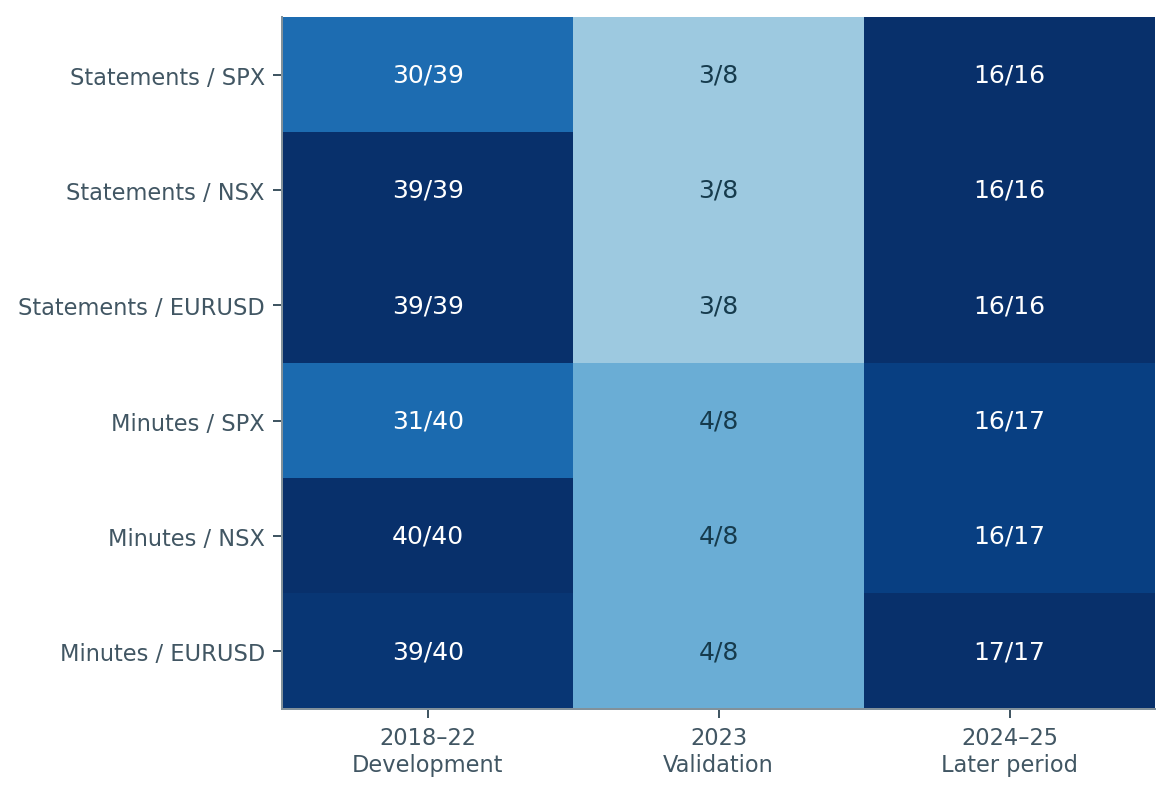

Figure 2. Accepted event windows divided by planned events. Every required minute from −61 to +25 must be present and valid; missing bars are never filled.

In [2]:
summary = json.loads((ROOT/'outputs/research-summary.json').read_text())
show_json({k:summary[k] for k in ['scheduled_statement_events','minutes_events','accepted_event_asset_pairs','planned_event_asset_pairs','source_archives','archived_source_bytes']})
coverage = table('coverage.csv')
show_table(coverage[['phase','event_type','asset','accepted','planned','coverage','sample_gate']], 'Table N01.1. Complete-window coverage and sample eligibility.')
assert coverage.accepted.sum() == 336
assert coverage.planned.sum() == 384
show_figure(2)

## Why the documented time zone failed

HistData's specification describes fixed Eastern Standard Time. The archived quotes did not follow that interpretation in summer. An external window comparison triggered a minute-by-minute audit against a separate Dukascopy route. In September 2022, SPX/SPY minute-return correlation rose from −0.0037 to 0.9995 after looking up source observations one hour later. March 2022, when the US and Europe were on different seasonal clocks, distinguished their daylight-saving calendars.

As Kebe and Uhl (2024) report in *High-frequency effects of novel news on the EURUSD exchange rate*, HistData daylight adjustments can contradict its documentation. Their observation corroborates the mismatch. The specific European calendar mapping used here is our inference from the probes, not a rule established by that article. Some routes may share underlying quotes; route agreement is not proof of independent price formation.

histdata,comparison,date,shift_minutes,paired_returns,return_correlation
SPXUSD,SPYUSUSD,2022-09-21,0,120,-0.003680
SPXUSD,SPYUSUSD,2022-09-21,60,120,0.999518
SPXUSD,SPYUSUSD,2022-03-16,0,120,0.996400
SPXUSD,SPYUSUSD,2022-03-16,60,104,0.024246
NSXUSD,QQQUSUSD,2022-09-21,0,120,0.004653
NSXUSD,QQQUSUSD,2022-09-21,60,120,0.999698
EURUSD,EURUSD,2022-09-21,0,120,0.025793
EURUSD,EURUSD,2022-09-21,60,120,1.000000
EURUSD,EURUSD,2022-03-16,0,120,1.000000
EURUSD,EURUSD,2022-03-16,60,120,0.026562


Equation (19). Audited source-clock mapping.
T_{\mathrm{UTC}}=T_{\mathrm{source}}+5\,\mathrm{hours}-d_{\mathrm{Europe}}(T_{\mathrm{source}})
dEurope is one hour during European summer time and zero otherwise. A02 records the evidence, scope and retrospective nature of this correction.

source_stamp,audited_utc
2022-03-16 09:00:00,2022-03-16 14:00:00+00:00
2022-09-21 10:00:00,2022-09-21 14:00:00+00:00
2022-11-02 10:00:00,2022-11-02 15:00:00+00:00


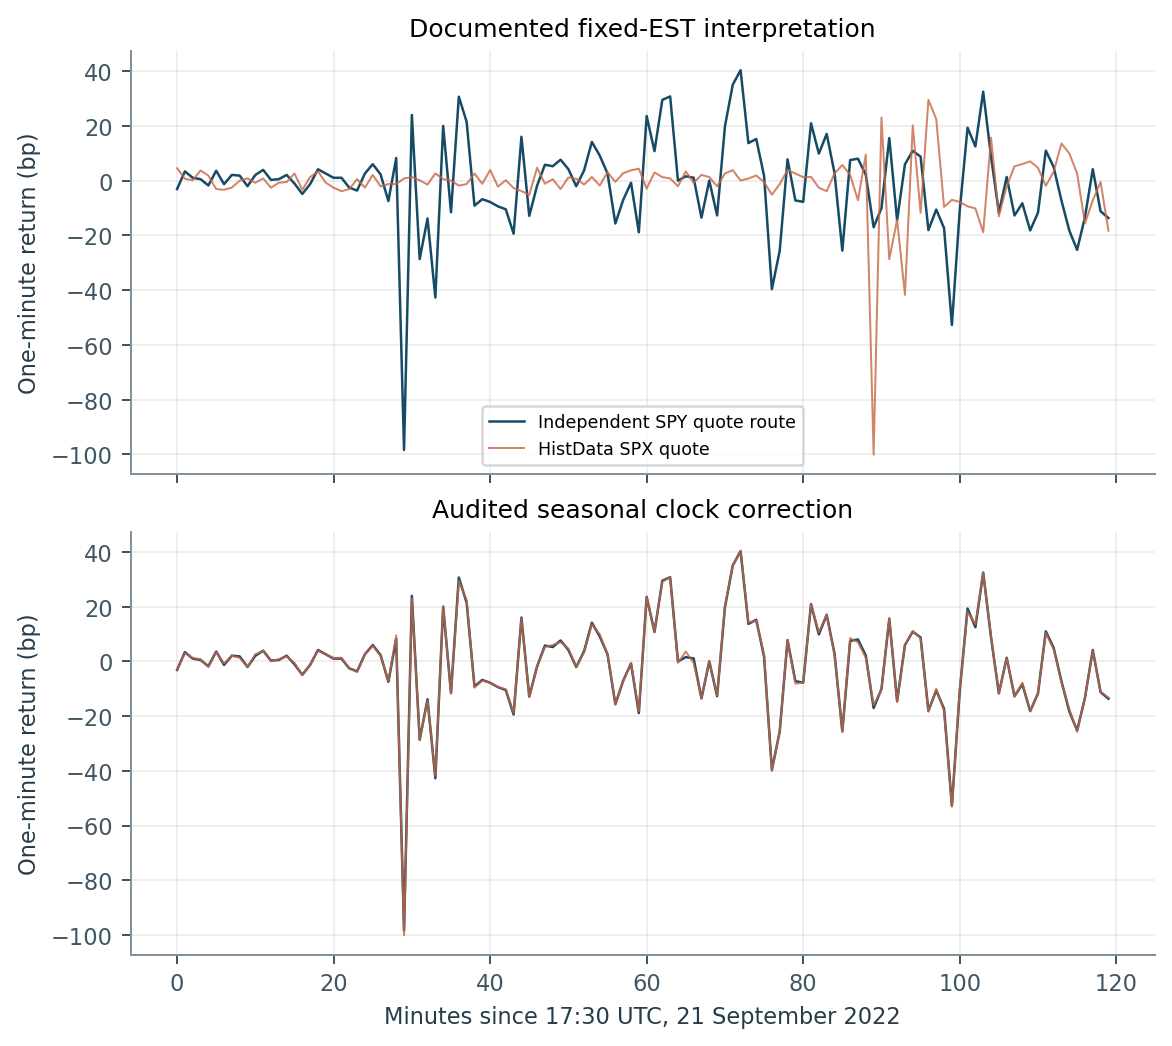

Figure 12. Independent download routes show that the documented clock misaligns the two series. Correcting the seasonal offset raises their minute-return correlation from −0.004 to 0.9995 on this probe. This checks timing rather than proving source independence or universal data quality.

In [3]:
probes = table('clock-probe-summary.csv')
show_table(probes, 'Table N01.2. Independently downloaded minute-quote clock probes.', decimals=6)
equation(19)
from diffusion.histdata import source_clock_to_utc
source = pd.Series(pd.to_datetime(['2022-03-16 09:00','2022-09-21 10:00','2022-11-02 10:00']))
mapped = source_clock_to_utc(source)
show_table(pd.DataFrame({'source_stamp':source.astype(str),'audited_utc':mapped.astype(str)}), 'Table N01.3. Deterministic source-to-UTC conversion examples.')
show_figure(12)

## What was corrected, and what remains uncertain

A02 applies one calendar rule to all three series and to events and matched controls. No event-specific offset is selected to improve a return result. The entire earlier run is retained in `archive/documented-clock-run/`. Corrected development models were frozen before corrected later predictions were recalculated, but the earlier outcome inspection means the later sample is no longer untouched.

All required bars from −61 through +25 must exist and satisfy quote checks. Extended plots preserve gaps rather than filling them. The three accepted 2023 statement observations are insufficient for the declared regression threshold of six. Better timestamp alignment does not repair absent bars or make missingness random.

event_id,event_type,date,asset,phase,event_accepted,control_accepted,control_reason,event_reason,flat_pre_fraction,flat_post_fraction,control_date,control_candidate
minutes_2018-01-03,Minutes,2018-01-03,SPX,development,False,False,event excluded,missing_required=8;invalid_required=8,—,—,—,—
statements_2018-01-31,Statements,2018-01-31,SPX,development,False,False,event excluded,missing_required=1;invalid_required=1,—,—,—,—
minutes_2018-02-21,Minutes,2018-02-21,SPX,development,False,False,event excluded,missing_required=1;invalid_required=1,—,—,—,—
statements_2018-03-21,Statements,2018-03-21,SPX,development,False,False,event excluded,missing_required=1;invalid_required=1,—,—,—,—
statements_2018-06-13,Statements,2018-06-13,SPX,development,False,False,event excluded,missing_required=5;invalid_required=5,—,—,—,—
minutes_2018-07-05,Minutes,2018-07-05,SPX,development,False,False,event excluded,missing_required=2;invalid_required=2,—,—,—,—
statements_2018-08-01,Statements,2018-08-01,SPX,development,False,False,event excluded,missing_required=6;invalid_required=6,—,—,—,—
minutes_2018-08-22,Minutes,2018-08-22,SPX,development,False,False,event excluded,missing_required=8;invalid_required=8,—,—,—,—
statements_2018-09-26,Statements,2018-09-26,SPX,development,False,False,event excluded,missing_required=6;invalid_required=6,—,—,—,—
minutes_2019-04-10,Minutes,2019-04-10,SPX,development,False,False,event excluded,missing_required=2;invalid_required=2,—,—,—,—


phase,event_type,asset,accepted,n,mean_absolute_surprise
development,Minutes,EURUSD,True,39,0.235
development,Minutes,EURUSD,False,1,0.319
development,Minutes,NSX,True,40,0.238
development,Minutes,SPX,True,31,0.257
development,Minutes,SPX,False,9,0.171
development,Statements,EURUSD,True,39,0.641
development,Statements,NSX,True,39,0.641
development,Statements,SPX,True,30,0.676
development,Statements,SPX,False,9,0.527
holdout,Minutes,EURUSD,True,17,0.274


event_type,source_field,n,correlation,mean_difference_bps,median_absolute_difference_bps,rmse_difference_bps
Minutes,SP500,51,0.981,-0.876,1.907,4.754
Minutes,SPFUT,51,0.968,-1.003,1.889,6.212
Statements,SP500,49,0.995,-0.169,2.168,4.579
Statements,SPFUT,49,0.993,0.148,3.556,5.282


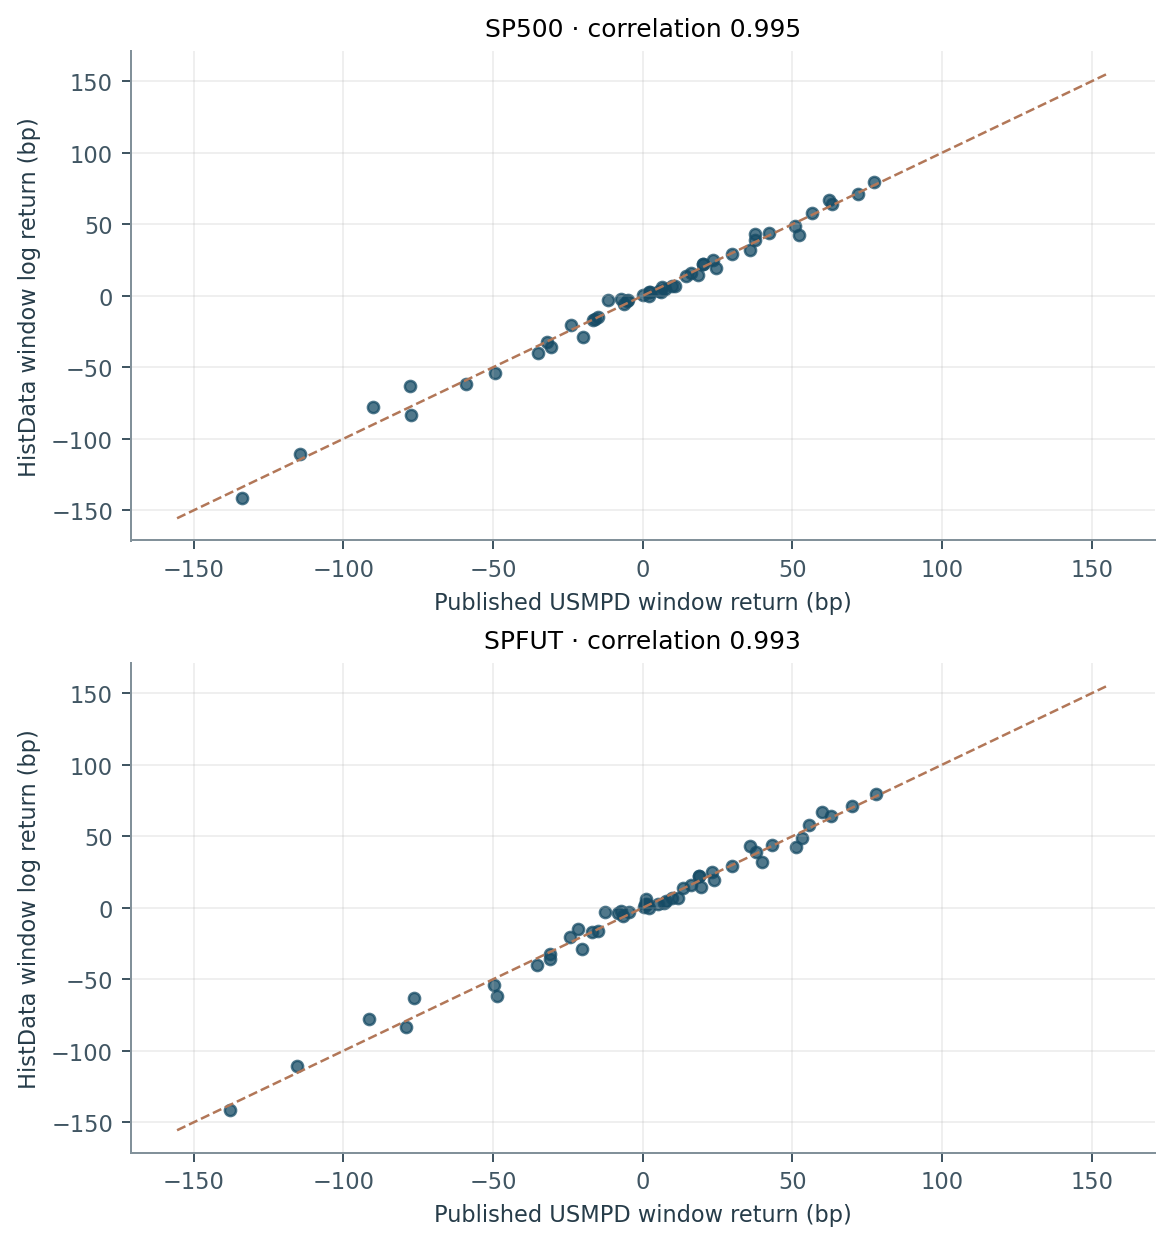

Figure 6. The same nominal −10-to-+20-minute window compared with USMPD stock-index and futures returns. Agreement supports alignment; different instruments, quote conventions and boundary sampling prevent treating it as minute-level ground truth.

In [4]:
audit = table('all-exclusions-and-controls.csv')
excluded = audit[~audit.event_accepted]
show_table(excluded.head(12), 'Table N01.4. First 12 exclusions; the full exclusion register is retained.')
show_table(table('missingness-surprise.csv'), 'Table N01.5. Surprise magnitude by coverage status; descriptive, not a missing-at-random test.')
cross = table('window-crosscheck-summary.csv')
show_table(cross, 'Table N01.6. Published-window agreement after A02.')
assert cross.query("event_type=='Statements' and source_field=='SP500'").correlation.iloc[0] > .99
show_figure(6)

## Reproduction and outcome

`scripts/acquire_histdata.py` retrieves free annual files through the ordinary public download form, caches exact bytes and records hashes. There are no credentials or paid keys. `scripts/audit_clocks.py` reproduces the selected minute probes. Raw files are packaged separately so notebook review does not require a 100 MB download or a live source connection.

The corrected 30-minute SPX/USMPD statement-window correlation is 0.9949. This is useful alignment evidence, not proof of every minute's correctness: USMPD contains different instruments and simple percentage returns, whereas these bars produce log returns. The primary development and pooled SPX samples still fail the 80% coverage rule.